[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_lppl_tc/BA_L2_lppl_tc.ipynb)

# BA_L2_lppl_tc: $\hat t_c$ across Estimation Windows

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Stability of the LPPL critical time: the model is re-estimated on eleven windows starting on 1 January 2017 and ending weekly from 1 October to 10 December 2017 (Bitcoin daily close, 120 random starts each), and the estimated critical times are compared with the actual peak.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Model and estimation

The **log-periodic power law** (LPPL) describes the log price before a critical time $t_c$:

$$\ln P_t = A + B\,(t_c - t)^m + C\,(t_c - t)^m \cos\!\big(\omega \ln(t_c - t) - \phi\big) + \varepsilon_t, \qquad t < t_c.$$

$B < 0$ and $0 < m < 1$ give super-exponential growth; $C$ is the amplitude and $\omega$ the log-frequency of
oscillations that speed up towards $t_c$. With $C_1 = C\cos\phi$ and $C_2 = C\sin\phi$ the model is linear in
$(A, B, C_1, C_2)$ for given $(t_c, m, \omega)$:

$$\ln P_t = A + B f_t + C_1 g_t + C_2 h_t + \varepsilon_t, \quad f_t = (t_c - t)^m,\ g_t = f_t\cos(\omega\ln(t_c - t)),\ h_t = f_t\sin(\omega\ln(t_c - t)).$$

Estimation has two steps: ordinary least squares (OLS) for $(A, B, C_1, C_2)$, and a Nelder–Mead search over
$(t_c, m, \omega)$ that minimises the sum of squared errors, restricted to $0.1 \le m \le 0.9$, $6 \le \omega \le 13$
and $t_c$ after the last observation. The search has many local minima, so it starts from many random points.
$t_c$ is the critical time implied by the fitted model, not a guaranteed date of the crash.

Here: eleven weekly window ends, 1 October to 10 December 2017, all starting on 1 January 2017, with 120 random
starts each (random seed 11). A fit is **at a bound** if $m$ or $\omega$ ends within 0.1 of a bound of the search,
or if $\hat t_c$ is less than about one day (0.003 years) after the last observation; such fits are poorly identified.

**How to read the chart.** Blue: $\hat t_c$ for each window end; red circles: fits at a bound; dashed orange: the
actual peak; dotted green: the window end, below which $\hat t_c$ cannot fall. A reliable early warning would give
stable, interior estimates close to the peak.

In [5]:
from scipy.optimize import minimize

p_btc = prices('BTC-USD.CC')
T0 = pd.Timestamp('2017-01-01')          # time t is in years since 1 January 2017


def design(t, tc, m, om):
    # regressors of the linear part: 1, f_t, g_t, h_t
    dt = tc - t; f = dt ** m
    return np.column_stack([np.ones_like(t), f, f * np.cos(om * np.log(dt)), f * np.sin(om * np.log(dt))])


def sse(th, t, y):
    # sum of squared errors after OLS for (A, B, C1, C2); infinite outside the bounds
    tc, m, om = th
    if tc <= t[-1] + 1e-3 or not (0.1 <= m <= 0.9) or not (6 <= om <= 13):
        return 1e9
    X = design(t, tc, m, om); coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return float(((y - X @ coef) ** 2).sum())


def lppl_fit(end, rng, starts, maxiter=4000):
    # best of `starts` Nelder-Mead searches over (t_c, m, omega) from random starting points
    s_ = p_btc.loc[T0:end]
    t = ((s_.index - T0).days.values / 365.25).astype(float); y = np.log(s_.values)
    best = None
    for _ in range(starts):
        x0 = [t[-1] + rng.uniform(0.005, 0.25), rng.uniform(0.1, 0.9), rng.uniform(6, 13)]
        r_ = minimize(sse, x0, args=(t, y), method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': maxiter})
        if best is None or r_.fun < best.fun:
            best = r_
    tc, m, om = best.x
    coef = np.linalg.lstsq(design(t, tc, m, om), y, rcond=None)[0]
    resid = y - design(t, tc, m, om) @ coef
    tcd = T0 + pd.Timedelta(days=tc * 365.25)
    return dict(end=pd.Timestamp(end), n=len(y), tc=tcd, lead=(tcd - pd.Timestamp(end)).days, m=m, omega=om,
                B=coef[1], C_over_B=np.hypot(coef[2], coef[3]) / abs(coef[1]),
                R2=1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum(), t=t, theta=(tc, m, om), coef=coef)

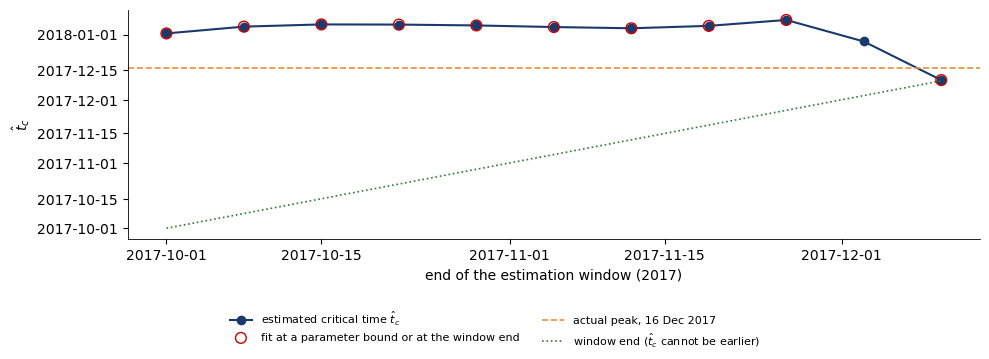

In [6]:
rng = np.random.default_rng(11)
ends = pd.date_range('2017-10-01', '2017-12-15', freq='7D')
rows = []
for e in ends:
    f_ = lppl_fit(e, rng, 120, maxiter=3000)
    tcy = f_['theta'][0]
    rows.append({'window end': e, 't_c': f_['tc'], 'm': f_['m'], 'omega': f_['omega'],
                 'at a bound': f_['m'] > 0.89 or f_['m'] < 0.11 or f_['omega'] > 12.9 or f_['omega'] < 6.1 or tcy - f_['t'][-1] < 0.003,
                 'at m = 0.9 and omega = 13': f_['m'] > 0.89 and f_['omega'] > 12.9,
                 't_c at window end': tcy - f_['t'][-1] < 0.003})
W = pd.DataFrame(rows)
peak = p_btc.loc['2017-11-01':'2018-01-31'].idxmax()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(W['window end'], W['t_c'], color=BLUE, marker='o', label=r'estimated critical time $\hat t_c$')
wb = W[W['at a bound']]
ax.scatter(wb['window end'], wb['t_c'], color=RED, s=60, zorder=5, facecolors='none',
           label='fit at a parameter bound or at the window end')
ax.axhline(peak, color=BTC, ls='--', lw=1.2, label=f'actual peak, {peak:%d %b %Y}')
ax.plot(W['window end'], W['window end'], color=GREEN, ls=':', lw=1.2, label=r'window end ($\hat t_c$ cannot be earlier)')
ax.set_xlabel('end of the estimation window (2017)'); ax.set_ylabel(r'$\hat t_c$')
slide_legend(fig, 0.16, ncol=2)
save_fig(fig, 'ba_l2_lppl_tc')

In [7]:
print(W.assign(**{'window end': W['window end'].dt.date, 't_c': W['t_c'].dt.date})
       [['window end', 't_c', 'm', 'omega', 'at a bound']].round(2).to_string(index=False))
print(f"\nFits at the bounds m = 0.9 and omega = 13: {int(W['at m = 0.9 and omega = 13'].sum())} of {len(W)}; "
      f"fits with t_c at the window end: {int(W['t_c at window end'].sum())}; interior fits: {int((~W['at a bound']).sum())}")

window end        t_c    m  omega  at a bound
2017-10-01 2018-01-01 0.90  13.00        True
2017-10-08 2018-01-04 0.90  13.00        True
2017-10-15 2018-01-05 0.90  13.00        True
2017-10-22 2018-01-05 0.90  13.00        True
2017-10-29 2018-01-05 0.90  13.00        True
2017-11-05 2018-01-04 0.90  13.00        True
2017-11-12 2018-01-03 0.90  13.00        True
2017-11-19 2018-01-05 0.90  13.00        True
2017-11-26 2018-01-07 0.90  13.00        True
2017-12-03 2017-12-28 0.82  12.68       False
2017-12-10 2017-12-10 0.71  11.32        True

Fits at the bounds m = 0.9 and omega = 13: 9 of 11; fits with t_c at the window end: 1; interior fits: 1
